<a href="https://colab.research.google.com/github/nishitasamania1212-cell/IBM_training_ai/blob/main/Credit_Card_Dataset_for_Clustering_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loaded real dataset from '/content/Customer_Data.csv' -> shape (8950, 18)
   CUSTID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4  C10005   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.000000

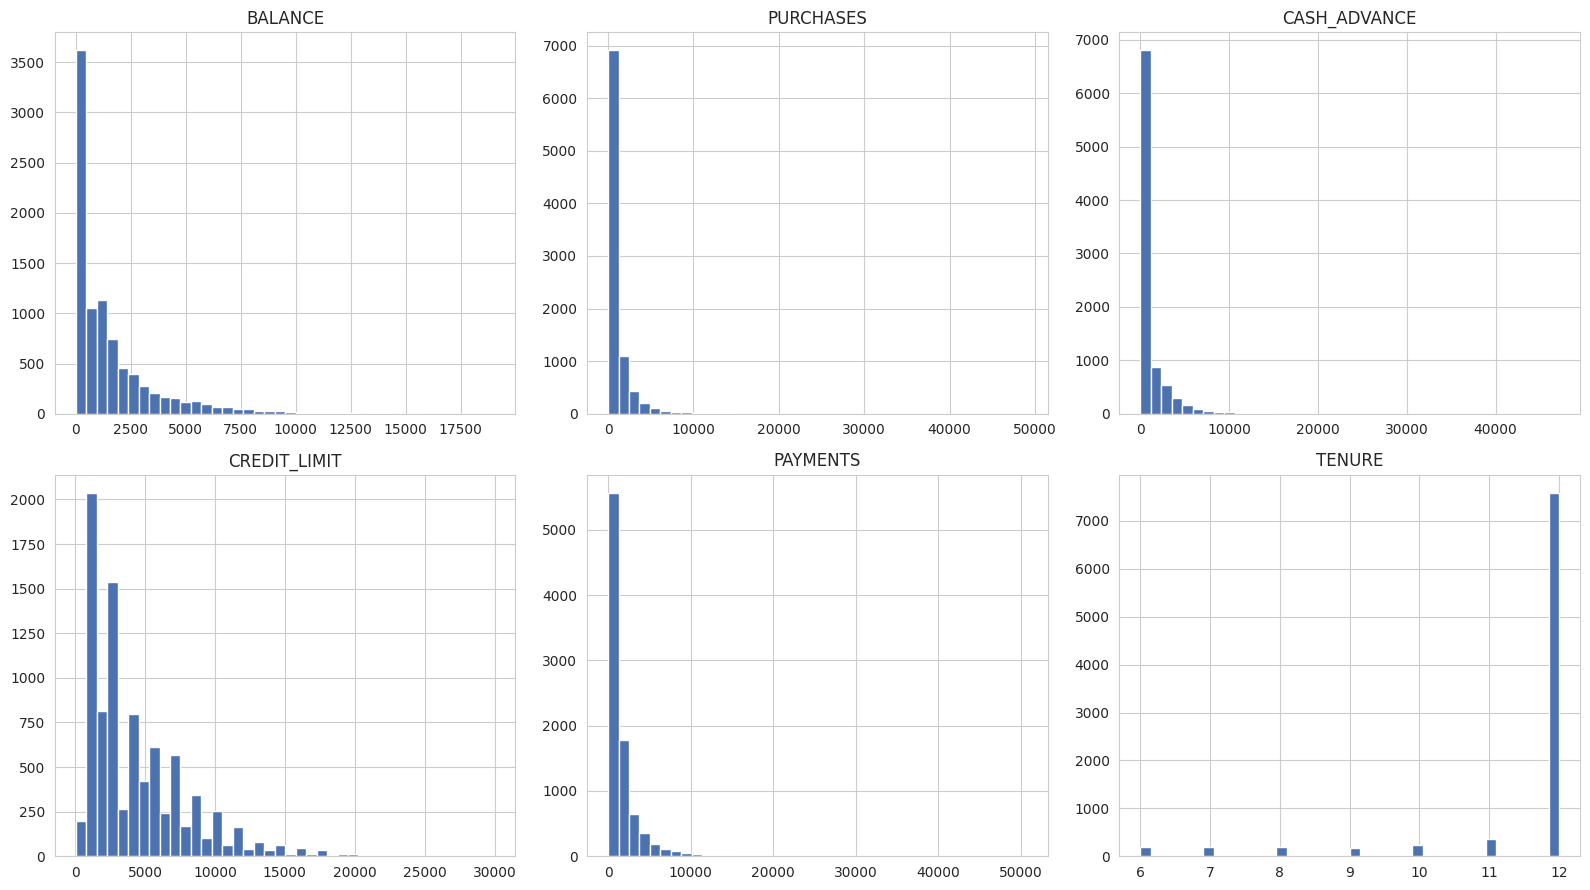

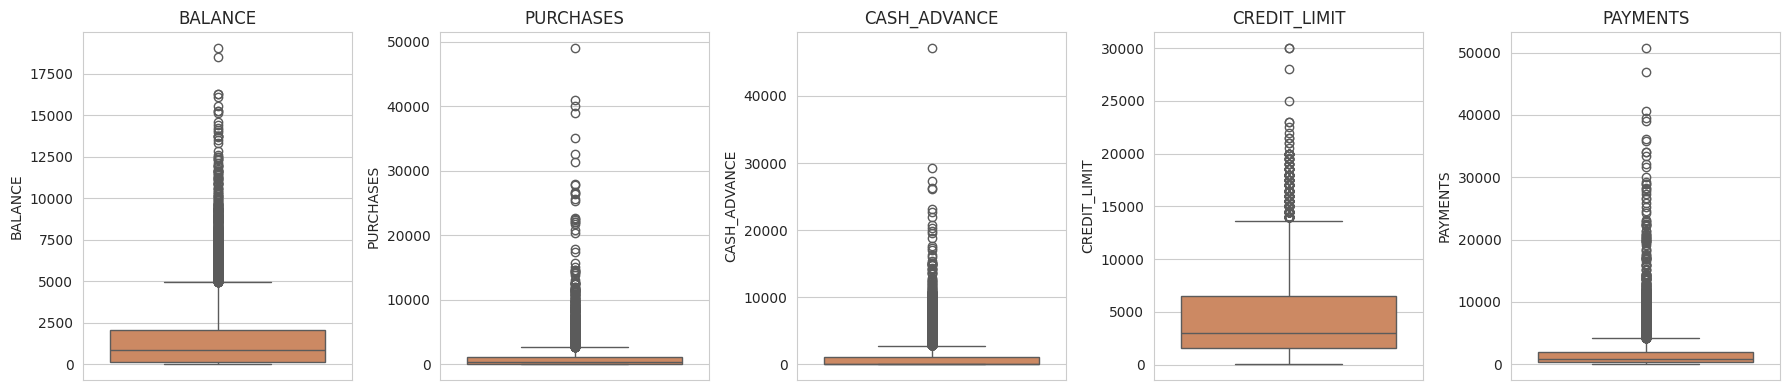

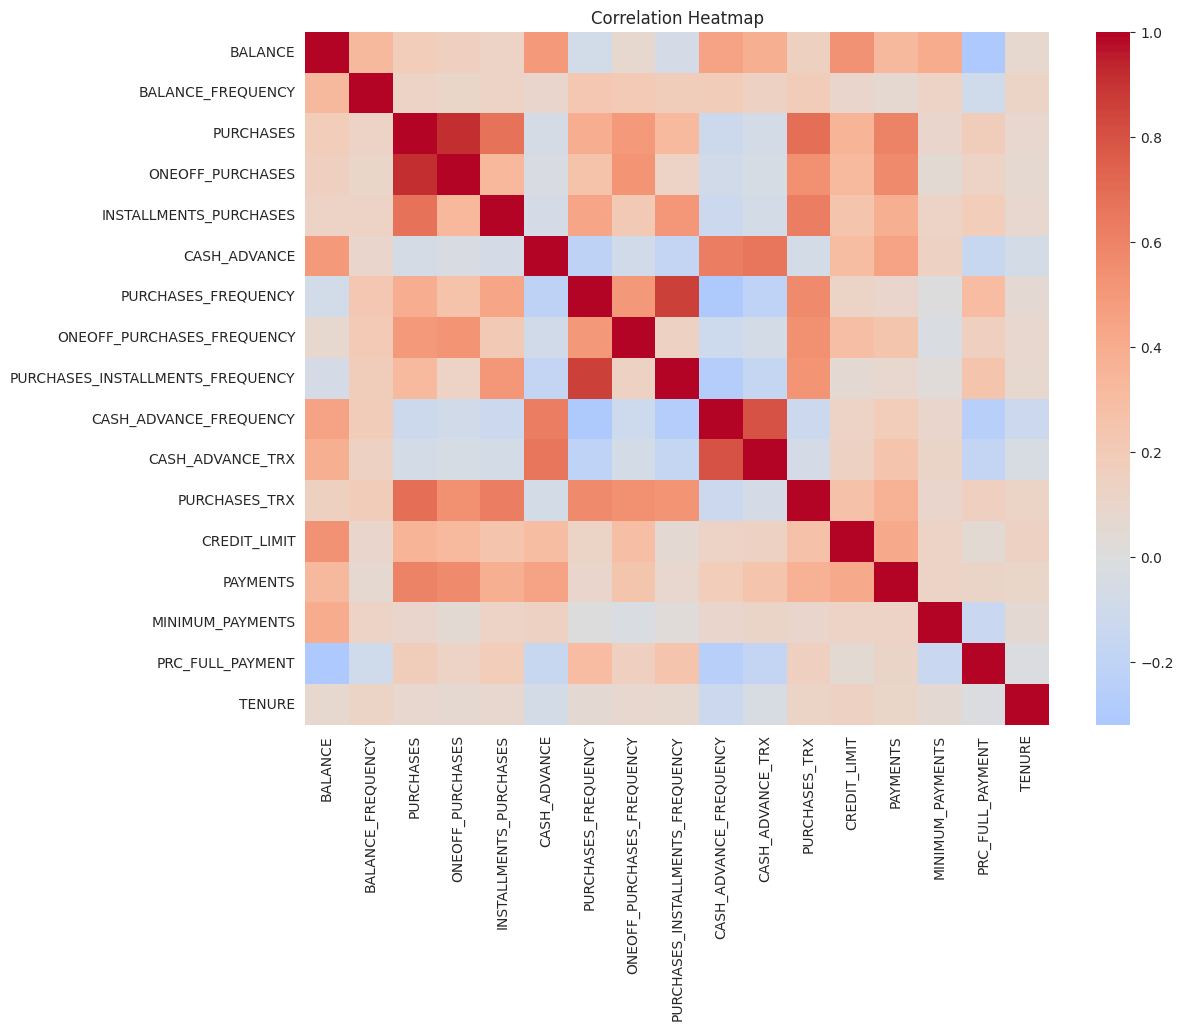

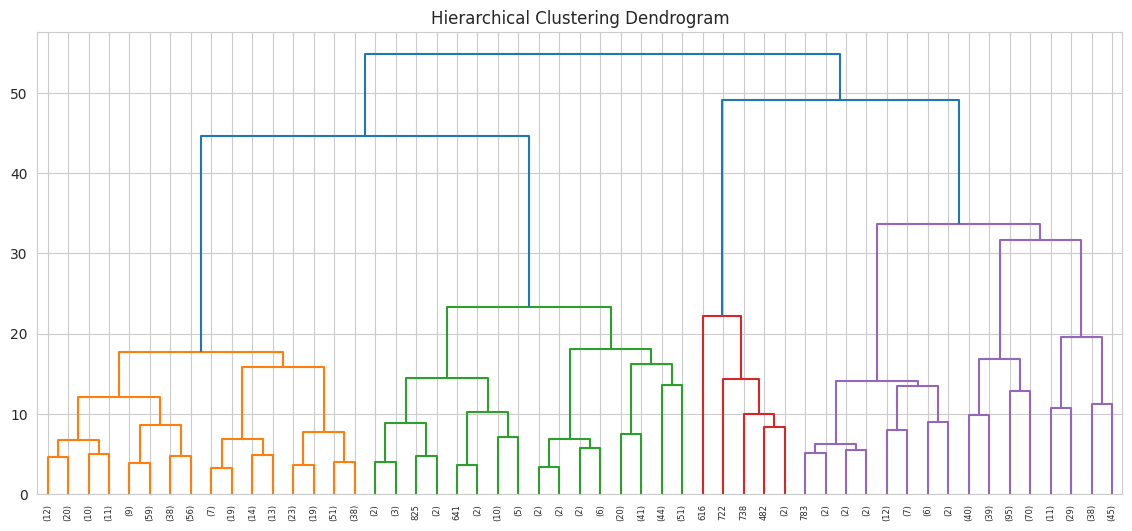

k=2: silhouette = 0.3590
k=3: silhouette = 0.1857
k=4: silhouette = 0.2096
k=5: silhouette = 0.2069
k=6: silhouette = 0.2110
k=7: silhouette = 0.2119
Cluster
0    3686
1     556
2    3484
3    1224
Name: count, dtype: int64
         BALANCE  PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
Cluster                                                          
0         546.94    1056.91        158.25                 0.79   
1        3431.62    5924.14        449.41                 0.93   
2        1124.09     225.43        905.54                 0.14   
3        5034.09     820.02       3899.37                 0.39   

         CASH_ADVANCE_FREQUENCY  PURCHASES_TRX  CREDIT_LIMIT  PAYMENTS  \
Cluster                                                                  
0                          0.04          18.05       4032.10   1193.09   
1                          0.05          74.94       9101.80   5841.88   
2                          0.17           2.41       2903.70   1015.78   
3        

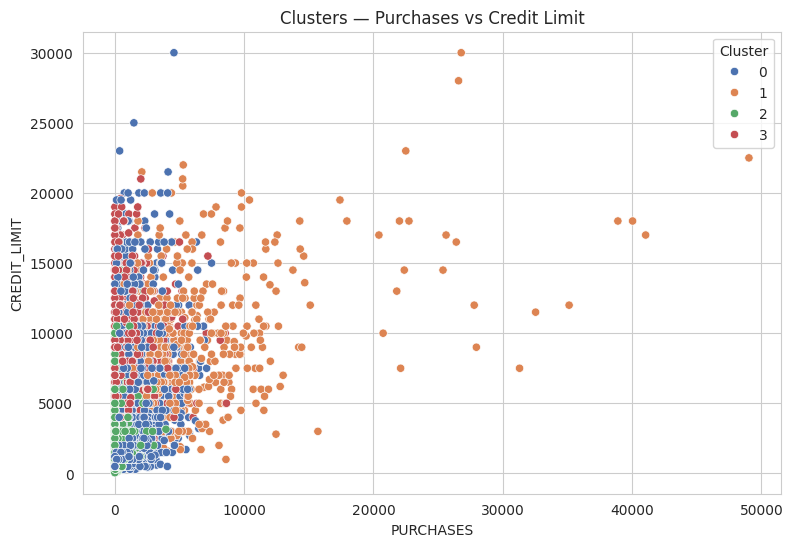

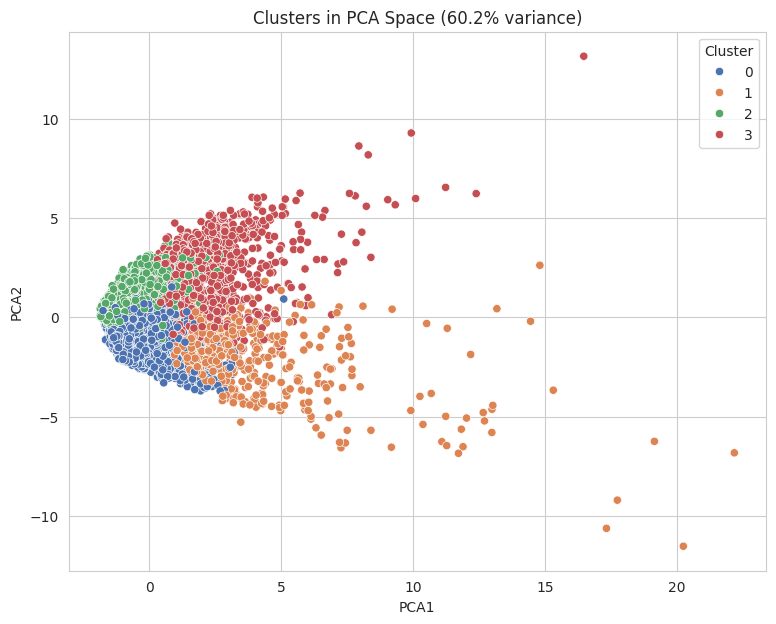

K = 4, Silhouette = 0.2114
Cluster
0    41.2
1     6.2
2    38.9
3    13.7
Name: proportion, dtype: float64 % each


In [2]:
#Credit Card Dataset for Clustering
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', 50)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---------------------------------------------------------------
# 2. Load dataset
# ---------------------------------------------------------------
DATA_PATH = "/content/Customer_Data.csv"

def make_synthetic_dataset(n=2000, seed=RANDOM_STATE):
    """Fallback dataset with the same schema, used only if DATA_PATH is not found."""
    rng = np.random.default_rng(seed)
    group = rng.choice(['low', 'regular', 'premium', 'cash_heavy'], size=n,
                        p=[0.35, 0.30, 0.20, 0.15])

    balance = rng.gamma(2.0, 800, n) + np.where(group == 'premium', 2500, 0)
    purchases = rng.gamma(2.0, 400, n) + np.where(group == 'premium', 3000, 0) \
                + np.where(group == 'low', -300, 0)
    purchases = np.clip(purchases, 0, None)
    oneoff = purchases * rng.uniform(0.2, 0.6, n)
    installments = np.clip(purchases - oneoff, 0, None)
    cash_advance = rng.gamma(1.5, 300, n) + np.where(group == 'cash_heavy', 3500, 0)
    credit_limit = rng.gamma(3.0, 1500, n) + np.where(group == 'premium', 5000, 0)
    payments = purchases * rng.uniform(0.5, 1.3, n) + cash_advance * rng.uniform(0.3, 0.9, n)
    min_payments = payments * rng.uniform(0.02, 0.1, n)
    prc_full_payment = np.clip(rng.beta(2, 5, n) + np.where(group == 'premium', 0.3, 0), 0, 1)
    tenure = rng.choice([6, 7, 8, 9, 10, 11, 12], size=n, p=[.02,.03,.05,.05,.1,.15,.6])

    df_ = pd.DataFrame({
        'CUST_ID': [f'C{100000+i}' for i in range(n)],
        'BALANCE': balance,
        'BALANCE_FREQUENCY': np.clip(rng.beta(5, 1.5, n), 0, 1),
        'PURCHASES': purchases,
        'ONEOFF_PURCHASES': oneoff,
        'INSTALLMENTS_PURCHASES': installments,
        'CASH_ADVANCE': cash_advance,
        'PURCHASES_FREQUENCY': np.clip(rng.beta(2, 2, n), 0, 1),
        'ONEOFF_PURCHASES_FREQUENCY': np.clip(rng.beta(2, 3, n), 0, 1),
        'PURCHASES_INSTALLMENTS_FREQUENCY': np.clip(rng.beta(2, 3, n), 0, 1),
        'CASH_ADVANCE_FREQUENCY': np.clip(rng.beta(1.2, 5, n) + np.where(group == 'cash_heavy', 0.3, 0), 0, 1),
        'CASH_ADVANCE_TRX': rng.poisson(2, n) + np.where(group == 'cash_heavy', 8, 0),
        'PURCHASES_TRX': rng.poisson(8, n) + np.where(group == 'premium', 15, 0),
        'CREDIT_LIMIT': credit_limit,
        'PAYMENTS': payments,
        'MINIMUM_PAYMENTS': min_payments,
        'PRC_FULL_PAYMENT': prc_full_payment,
        'TENURE': tenure,
    })
    for col in ['MINIMUM_PAYMENTS', 'CREDIT_LIMIT']:
        mask = rng.random(n) < 0.02
        df_.loc[mask, col] = np.nan
    return df_

try:
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded real dataset from '{DATA_PATH}' -> shape {df.shape}")
except FileNotFoundError:
    print(f"'{DATA_PATH}' not found — generating a synthetic dataset with the same schema.")
    df = make_synthetic_dataset()

print(df.head())

# ---------------------------------------------------------------
# 3. Initial inspection
# ---------------------------------------------------------------
print("Shape:", df.shape)
print(df.info())
print(df.describe().T)
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())

# ---------------------------------------------------------------
# 4. EDA
# ---------------------------------------------------------------
num_cols = df.select_dtypes(include=np.number).columns.tolist()
key_features = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), key_features + ['TENURE']):
    df[col].hist(bins=40, ax=ax, color='#4C72B0')
    ax.set_title(col)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(key_features), figsize=(18, 4))
for ax, col in zip(axes, key_features):
    sns.boxplot(y=df[col], ax=ax, color='#DD8452')
    ax.set_title(col)
plt.tight_layout(); plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(df[num_cols].corr(), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap'); plt.show()

# ---------------------------------------------------------------
# 5. Cleaning
# ---------------------------------------------------------------
for col in ['MINIMUM_PAYMENTS', 'CREDIT_LIMIT']:
    if col in df.columns and df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

df = df.drop_duplicates()
assert df.isnull().sum().sum() == 0

# ---------------------------------------------------------------
# 6-7. Feature selection & scaling
# ---------------------------------------------------------------
features = [
    'BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY',
    'CASH_ADVANCE_FREQUENCY', 'PURCHASES_TRX', 'CREDIT_LIMIT',
    'PAYMENTS', 'PRC_FULL_PAYMENT'
]
X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------------------------------------------------------------
# 8. Dendrogram
# ---------------------------------------------------------------
SAMPLE_SIZE = 1000
if len(X_scaled) > SAMPLE_SIZE:
    sample_idx = np.random.choice(len(X_scaled), SAMPLE_SIZE, replace=False)
    X_for_dendro = X_scaled[sample_idx]
else:
    X_for_dendro = X_scaled

linked = linkage(X_for_dendro, method='ward')
plt.figure(figsize=(14, 6))
dendrogram(linked, truncate_mode='level', p=5)
plt.title('Hierarchical Clustering Dendrogram'); plt.show()

# ---------------------------------------------------------------
# 9. Choose k via silhouette score
# ---------------------------------------------------------------
SIL_SAMPLE = 3000
scores = {}
for k in range(2, 8):
    model = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = model.fit_predict(X_scaled)
    if len(X_scaled) > SIL_SAMPLE:
        idx = np.random.choice(len(X_scaled), SIL_SAMPLE, replace=False)
        s = silhouette_score(X_scaled[idx], labels[idx])
    else:
        s = silhouette_score(X_scaled, labels)
    scores[k] = s
    print(f"k={k}: silhouette = {s:.4f}")

K_FINAL = 4  # <-- set based on your own results

# ---------------------------------------------------------------
# 10. Fit final model
# ---------------------------------------------------------------
model = AgglomerativeClustering(n_clusters=K_FINAL, metric='euclidean', linkage='ward')
df['Cluster'] = model.fit_predict(X_scaled)
print(df['Cluster'].value_counts().sort_index())

# ---------------------------------------------------------------
# 11. Cluster profiling
# ---------------------------------------------------------------
profile = df.groupby('Cluster')[features].mean().round(2)
profile['n_customers'] = df['Cluster'].value_counts().sort_index()
print(profile)

cluster_labels = {c: f"Cluster {c}" for c in sorted(df['Cluster'].unique())}
# e.g. {0: 'Low Activity', 1: 'Regular Purchasers', 2: 'Premium', 3: 'Cash-Advance Heavy'}
df['Segment'] = df['Cluster'].map(cluster_labels)

# ---------------------------------------------------------------
# 12. Visualization (2-feature + PCA)
# ---------------------------------------------------------------
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='PURCHASES', y='CREDIT_LIMIT', hue='Cluster', palette='deep')
plt.title('Clusters — Purchases vs Credit Limit'); plt.show()

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
df['PCA1'], df['PCA2'] = X_pca[:, 0], X_pca[:, 1]

plt.figure(figsize=(9, 7))
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', palette='deep', data=df)
plt.title(f'Clusters in PCA Space ({pca.explained_variance_ratio_.sum()*100:.1f}% variance)')
plt.show()

# ---------------------------------------------------------------
# 13. Evaluation summary
# ---------------------------------------------------------------
print(f"K = {K_FINAL}, Silhouette = {silhouette_score(X_scaled, df['Cluster']):.4f}")
print(df['Cluster'].value_counts(normalize=True).sort_index().round(3) * 100, "% each")